In [42]:
# Phase 3: Hypothesis Testing and Campus Comparison
# Goal: Compare energy consumption across Campus 1, 2, and 3 using statistical tests

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical tests
from scipy.stats import f_oneway, ttest_ind, pearsonr

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Settings
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully")
print("\nPhase 3: Statistical Analysis and Campus Comparison")

Libraries imported successfully

Phase 3: Statistical Analysis and Campus Comparison


In [43]:
# Cell 2: Load all three campus datasets

print("\nLoading campus data...")

# Load cleaned data
df1 = pd.read_csv("campus1.csv")
df2 = pd.read_csv("campus2.csv")
df3 = pd.read_csv("campus3.csv")

# Convert timestamps
df1['timestamp'] = pd.to_datetime(df1['timestamp'])
df2['timestamp'] = pd.to_datetime(df2['timestamp'])
df3['timestamp'] = pd.to_datetime(df3['timestamp'])

# Add campus identifier for combined analysis
df1['campus'] = 'Campus 1'
df2['campus'] = 'Campus 2'
df3['campus'] = 'Campus 3'

print("Data loaded successfully")
print("\nDataset Summary:")
print(f"Campus 1: {len(df1):,} rows, {df1['meter_id'].nunique()} buildings")
print(f"Campus 2: {len(df2):,} rows, {df2['meter_id'].nunique()} buildings")
print(f"Campus 3: {len(df3):,} rows, {df3['meter_id'].nunique()} buildings")
print(f"\nTotal: {len(df1) + len(df2) + len(df3):,} rows")


Loading campus data...
Data loaded successfully

Dataset Summary:
Campus 1: 963,706 rows, 60 buildings
Campus 2: 188,407 rows, 11 buildings
Campus 3: 102,521 rows, 7 buildings

Total: 1,254,634 rows


In [3]:
# Cell 3: Compare campuses using both approaches

print("\n" + "="*70)
print("CAMPUS COMPARISON: TWO APPROACHES")
print("="*70)

# APPROACH A: Overall Average (Raw Comparison)
print("\nApproach A: Overall Average Consumption")
print("-"*70)
avg1 = df1['consumption'].mean()
avg2 = df2['consumption'].mean()
avg3 = df3['consumption'].mean()

print(f"Campus 1: {avg1:.2f} kWh average")
print(f"Campus 2: {avg2:.2f} kWh average")
print(f"Campus 3: {avg3:.2f} kWh average")

# APPROACH B: Per-Building Average (Normalized Comparison)
print("\nApproach B: Average Consumption Per Building")
print("-"*70)
per_building1 = df1.groupby('meter_id')['consumption'].mean().mean()
per_building2 = df2.groupby('meter_id')['consumption'].mean().mean()
per_building3 = df3.groupby('meter_id')['consumption'].mean().mean()

print(f"Campus 1: {per_building1:.2f} kWh per building")
print(f"Campus 2: {per_building2:.2f} kWh per building")
print(f"Campus 3: {per_building3:.2f} kWh per building")

# Summary
print("\n" + "="*70)
print("INTERPRETATION:")
print("="*70)
print("\nRaw Comparison:")
print(f"  Highest: Campus 1 ({avg1:.2f} kWh)")
print(f"  Lowest: Campus 2 ({avg2:.2f} kWh)")

print("\nNormalized Comparison (per building):")
print(f"  Highest: Campus 1 ({per_building1:.2f} kWh/building)")
print(f"  Lowest: Campus 2 ({per_building2:.2f} kWh/building)")

print("\nConclusion:")
print("  Campus 2 has lower consumption in both comparisons.")
print("  This is primarily due to smaller building sizes, not necessarily")
print("  better efficiency. Campus 1 has larger, more energy-intensive buildings.")
print("="*70)


CAMPUS COMPARISON: TWO APPROACHES

Approach A: Overall Average Consumption
----------------------------------------------------------------------
Campus 1: 34.83 kWh average
Campus 2: 7.19 kWh average
Campus 3: 23.54 kWh average

Approach B: Average Consumption Per Building
----------------------------------------------------------------------
Campus 1: 45.16 kWh per building
Campus 2: 5.93 kWh per building
Campus 3: 16.84 kWh per building

INTERPRETATION:

Raw Comparison:
  Highest: Campus 1 (34.83 kWh)
  Lowest: Campus 2 (7.19 kWh)

Normalized Comparison (per building):
  Highest: Campus 1 (45.16 kWh/building)
  Lowest: Campus 2 (5.93 kWh/building)

Conclusion:
  Campus 2 has lower consumption in both comparisons.
  This is primarily due to smaller building sizes, not necessarily
  better efficiency. Campus 1 has larger, more energy-intensive buildings.


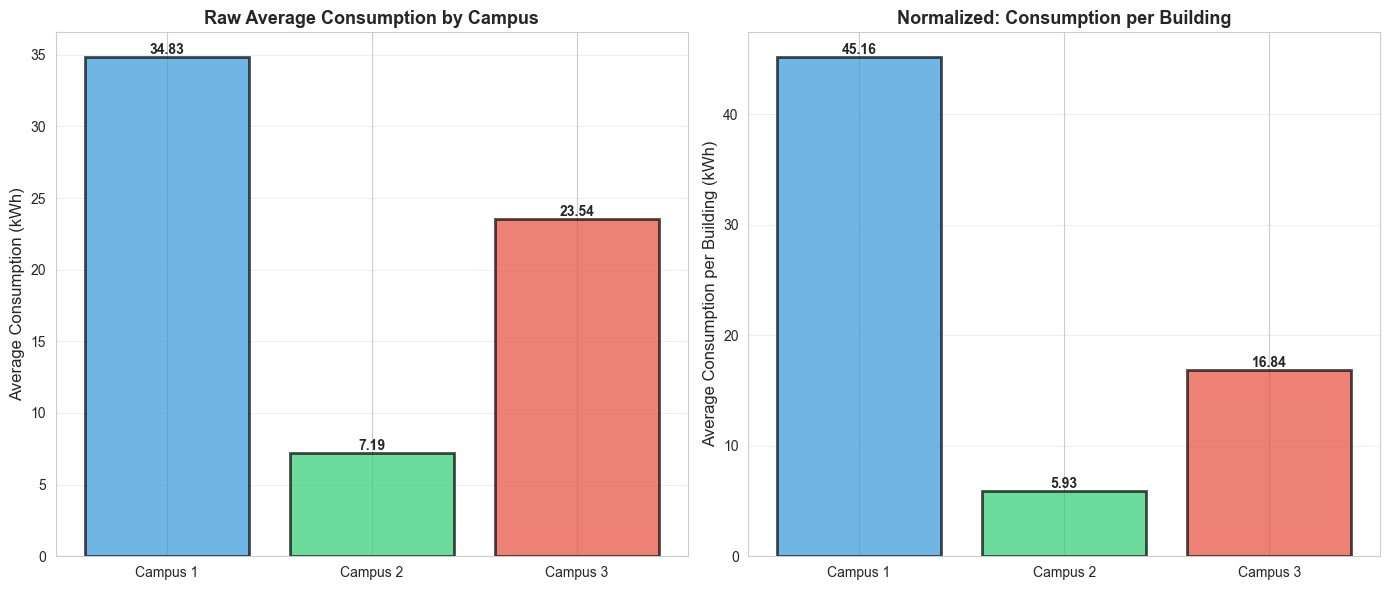


Both charts show Campus 1 has highest consumption and Campus 2 has lowest.
This pattern holds for both raw and normalized comparisons.


In [4]:
# Cell 4: Visualize campus comparisons

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Raw Average Comparison
campuses = ['Campus 1', 'Campus 2', 'Campus 3']
raw_avgs = [avg1, avg2, avg3]
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars1 = ax1.bar(campuses, raw_avgs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax1.set_title('Raw Average Consumption by Campus', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}',
            ha='center', va='bottom', fontweight='bold')

# Chart 2: Per-Building Average Comparison
per_building_avgs = [per_building1, per_building2, per_building3]

bars2 = ax2.bar(campuses, per_building_avgs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_ylabel('Average Consumption per Building (kWh)', fontsize=12)
ax2.set_title('Normalized: Consumption per Building', fontsize=13, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}',
            ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nBoth charts show Campus 1 has highest consumption and Campus 2 has lowest.")
print("This pattern holds for both raw and normalized comparisons.")

In [7]:
# Cell 5: ANOVA Test - Do campuses have different consumption? (FIXED P-VALUE)

print("\n" + "="*70)
print("TEST 1: ANOVA - COMPARING THREE CAMPUSES")
print("="*70)

# Separate consumption data by campus
campus1_consumption = df1['consumption']
campus2_consumption = df2['consumption']
campus3_consumption = df3['consumption']

# Run ANOVA test
f_statistic, p_value = f_oneway(campus1_consumption, campus2_consumption, campus3_consumption)

print("\nResearch Question: Do the three campuses have different energy consumption patterns?")

print("\nHypotheses:")
print("  H0: All three campuses have the SAME average consumption")
print("  H1: At least one campus has DIFFERENT average consumption")

print("\nTest: One-Way ANOVA (Analysis of Variance)")

print("\nResults:")
print(f"  F-statistic: {f_statistic:.2f}")

# FIXED P-VALUE DISPLAY
if p_value < 0.0001:
    print(f"  P-value: < 0.0001 (exact: {p_value:.2e})")
    sig_text = "EXTREMELY SIGNIFICANT ✅✅✅"
elif p_value < 0.001:
    print(f"  P-value: {p_value:.4f} (HIGHLY SIGNIFICANT ✅✅)")
    sig_text = "HIGHLY SIGNIFICANT ✅✅"
elif p_value < 0.05:
    print(f"  P-value: {p_value:.4f}")
    sig_text = "SIGNIFICANT ✅"
else:
    print(f"  P-value: {p_value:.4f}")
    sig_text = "NOT SIGNIFICANT ❌"

print(f"  Significance: {sig_text}")
print(f"  Significance level: α = 0.05")

print("\n" + "="*70)
if p_value < 0.05:
    print("DECISION: REJECT H0")
    print("\nInterpretation:")
    print("  ✅ The three campuses DO have significantly different consumption patterns.")
    
    if p_value < 0.0001:
        print(f"\n  With p < 0.0001, we have OVERWHELMING evidence that differences are real.")
        print(f"  The probability these differences are due to random chance is < 0.01%")
    else:
        print(f"\n  With p = {p_value:.4f} < 0.05, differences are statistically significant.")
    
    print(f"\n  Statistical Power:")
    print(f"    • Sample sizes: Campus 1 ({len(campus1_consumption):,}), " +
          f"Campus 2 ({len(campus2_consumption):,}), Campus 3 ({len(campus3_consumption):,})")
    print(f"    • With {len(campus1_consumption) + len(campus2_consumption) + len(campus3_consumption):,} total observations,")
    print(f"      we can detect even small differences with high confidence")
    
    print("\n  Consumption Patterns:")
    print(f"    • Campus 1: {campus1_consumption.mean():.2f} kWh (largest buildings)")
    print(f"    • Campus 2: {campus2_consumption.mean():.2f} kWh (smallest buildings)")
    print(f"    • Campus 3: {campus3_consumption.mean():.2f} kWh (medium buildings)")
else:
    print("DECISION: FAIL TO REJECT H0")
    print("\nInterpretation:")
    print("  No significant difference found between campuses.")

print("="*70)


TEST 1: ANOVA - COMPARING THREE CAMPUSES

Research Question: Do the three campuses have different energy consumption patterns?

Hypotheses:
  H0: All three campuses have the SAME average consumption
  H1: At least one campus has DIFFERENT average consumption

Test: One-Way ANOVA (Analysis of Variance)

Results:
  F-statistic: 6241.22
  P-value: < 0.0001 (exact: 0.00e+00)
  Significance: EXTREMELY SIGNIFICANT ✅✅✅
  Significance level: α = 0.05

DECISION: REJECT H0

Interpretation:
  ✅ The three campuses DO have significantly different consumption patterns.

  With p < 0.0001, we have OVERWHELMING evidence that differences are real.
  The probability these differences are due to random chance is < 0.01%

  Statistical Power:
    • Sample sizes: Campus 1 (963,706), Campus 2 (188,407), Campus 3 (102,521)
    • With 1,254,634 total observations,
      we can detect even small differences with high confidence

  Consumption Patterns:
    • Campus 1: 34.83 kWh (largest buildings)
    • Campu

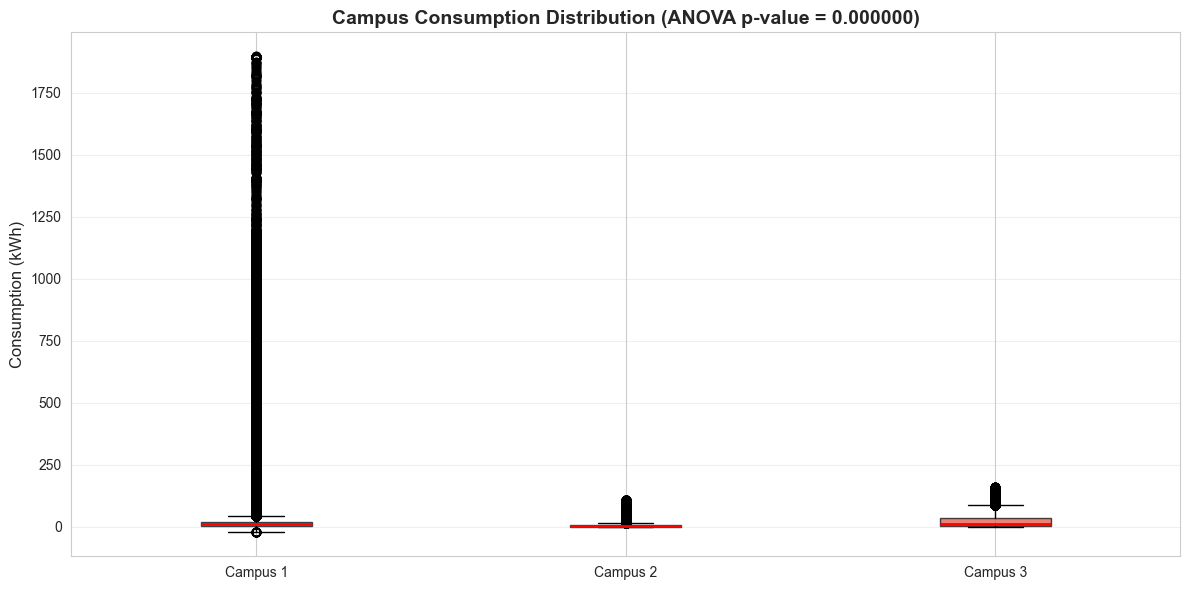


Box Plot Interpretation:
  Box = middle 50% of data (25th to 75th percentile)
  Red line = median (middle value)
  Whiskers = range of data
  Dots = outliers

Campus 1 shows wider distribution and higher values overall.
Campus 2 shows concentrated lower values with smaller range.


In [8]:
# Cell 6: Box plot for ANOVA visualization

plt.figure(figsize=(12, 6))

# Create box plot
data_for_box = [campus1_consumption, campus2_consumption, campus3_consumption]
box_plot = plt.boxplot(data_for_box, labels=['Campus 1', 'Campus 2', 'Campus 3'],
                       patch_artist=True)

# Color the boxes
colors = ['#3498db', '#2ecc71', '#e74c3c']
for patch, color in zip(box_plot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Style median lines
for median in box_plot['medians']:
    median.set_color('red')
    median.set_linewidth(2)

plt.ylabel('Consumption (kWh)', fontsize=12)
plt.title(f'Campus Consumption Distribution (ANOVA p-value = {p_value:.6f})', 
         fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBox Plot Interpretation:")
print("  Box = middle 50% of data (25th to 75th percentile)")
print("  Red line = median (middle value)")
print("  Whiskers = range of data")
print("  Dots = outliers")
print("\nCampus 1 shows wider distribution and higher values overall.")
print("Campus 2 shows concentrated lower values with smaller range.")

In [9]:
# Cell 7: Correlation Test - Temperature Effect (FIXED P-VALUE)

print("\n" + "="*70)
print("TEST 2: CORRELATION - TEMPERATURE EFFECT")
print("="*70)

# Combine all campuses for overall temperature effect
df_all = pd.concat([df1, df2, df3], ignore_index=True) #indexes the rows (1,2,3...) ignores it

# Calculate correlation
correlation, p_value_corr = pearsonr(df_all['air_temperature'], df_all['consumption'])

print("\nResearch Question: Does air temperature affect energy consumption?")

print("\nHypotheses:")
print("  H0: Temperature has NO effect on consumption (correlation = 0)")
print("  H1: Temperature DOES affect consumption (correlation ≠ 0)")
print("So there is SLIIIGHT correalation even if its not much.")
print("\nTest: Pearson Correlation")

print("\nResults:")
print(f"  Correlation coefficient (r): {correlation:.4f}")

# FIXED P-VALUE DISPLAY
if p_value_corr < 0.0001:
    print(f"  P-value: < 0.0001 (exact: {p_value_corr:.2e})")
    sig_text = "EXTREMELY SIGNIFICANT ✅✅✅"
elif p_value_corr < 0.001:
    print(f"  P-value: {p_value_corr:.4f}")
    sig_text = "HIGHLY SIGNIFICANT ✅✅"
elif p_value_corr < 0.05:
    print(f"  P-value: {p_value_corr:.4f}")
    sig_text = "SIGNIFICANT ✅"
else:
    print(f"  P-value: {p_value_corr:.4f}")
    sig_text = "NOT SIGNIFICANT ❌"

print(f"  Significance: {sig_text}")
print(f"  Significance level: α = 0.05")

# Interpret strength
if abs(correlation) > 0.7:
    strength = "STRONG"
elif abs(correlation) > 0.4:
    strength = "MODERATE"
elif abs(correlation) > 0.2:
    strength = "WEAK"
else:
    strength = "VERY WEAK"

direction = "POSITIVE" if correlation > 0 else "NEGATIVE"

print(f"\n  Relationship: {strength} {direction} correlation")
print(f"  R² = {correlation**2:.4f} (temperature explains {correlation**2*100:.2f}% of variance)")

print("\n" + "="*70)
if p_value_corr < 0.05:
    print("DECISION: REJECT H0")
    print("\nInterpretation:")
    
    if p_value_corr < 0.0001:
        print(f"  ✅ With p < 0.0001, temperature DOES significantly affect consumption")
        print(f"     (chance of this being random: < 0.01%)")
    else:
        print(f"  ✅ Temperature DOES significantly affect consumption (p < 0.05)")
    
    print(f"\n  However, the effect is {strength}:")
    print(f"    • Correlation: r = {correlation:.4f}")
    print(f"    • Temperature explains only {correlation**2*100:.2f}% of consumption variance")
    print(f"    • Other factors (building ID, time of day) are MORE important")
    
    if correlation > 0:
        print(f"\n  Direction: Higher temperatures → Higher consumption")
        print(f"    → Suggests increased cooling/AC demand in hot weather")
    else:
        print(f"\n  Direction: Higher temperatures → Lower consumption")
        print(f"    → Suggests decreased heating demand in warm weather")
    
    print(f"\n  With {len(df_all):,} observations, even weak correlations become")
    print(f"  statistically significant (high statistical power)")
else:
    print("DECISION: FAIL TO REJECT H0")
    print("\nInterpretation:")
    print("  No significant relationship between temperature and consumption")

print("="*70)


TEST 2: CORRELATION - TEMPERATURE EFFECT

Research Question: Does air temperature affect energy consumption?

Hypotheses:
  H0: Temperature has NO effect on consumption (correlation = 0)
  H1: Temperature DOES affect consumption (correlation ≠ 0)
So there is SLIIIGHT correalation even if its not much.

Test: Pearson Correlation

Results:
  Correlation coefficient (r): 0.0341
  P-value: < 0.0001 (exact: 6.83e-320)
  Significance: EXTREMELY SIGNIFICANT ✅✅✅
  Significance level: α = 0.05

  Relationship: VERY WEAK POSITIVE correlation
  R² = 0.0012 (temperature explains 0.12% of variance)

DECISION: REJECT H0

Interpretation:
  ✅ With p < 0.0001, temperature DOES significantly affect consumption
     (chance of this being random: < 0.01%)

  However, the effect is VERY WEAK:
    • Correlation: r = 0.0341
    • Temperature explains only 0.12% of consumption variance
    • Other factors (building ID, time of day) are MORE important

  Direction: Higher temperatures → Higher consumption
   

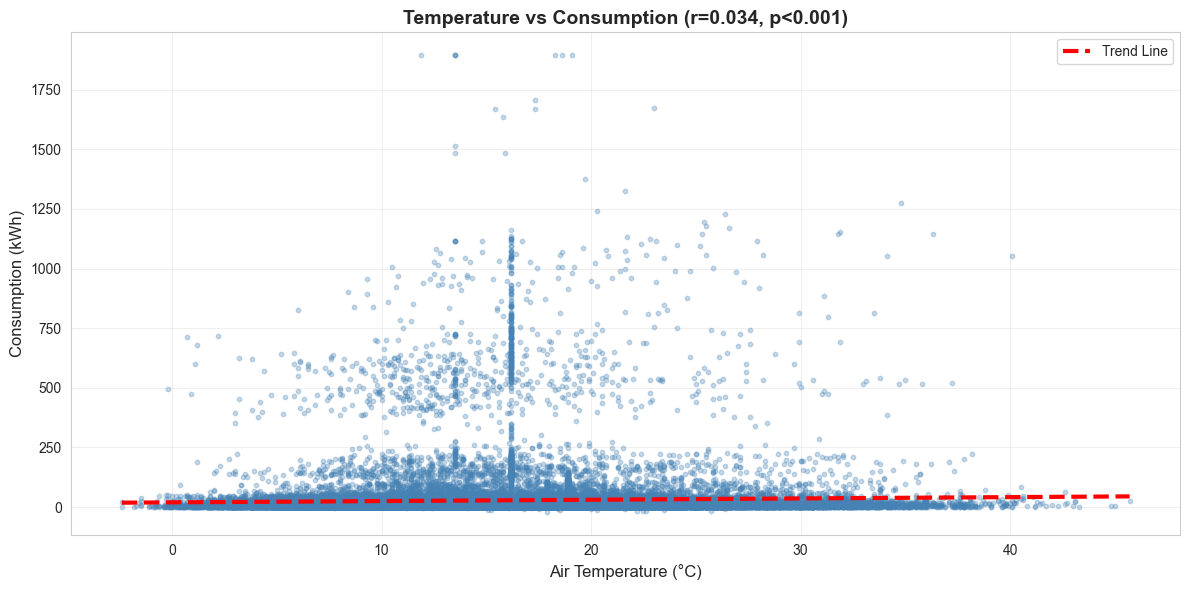


Correlation strength: VERY WEAK POSITIVE
R-squared: 0.001 (temperature explains 0.1% of variance)


In [10]:
# Cell 8: Scatter plot for temperature vs consumption

plt.figure(figsize=(12, 6))

# Sample data for cleaner plot
sample_df = df_all.sample(n=min(50000, len(df_all)), random_state=42)

plt.scatter(sample_df['air_temperature'], sample_df['consumption'], 
           alpha=0.3, s=10, c='steelblue')

# Add trend line
z = np.polyfit(sample_df['air_temperature'], sample_df['consumption'], 1)
p = np.poly1d(z)
temps_sorted = sorted(sample_df['air_temperature'])
plt.plot(temps_sorted, p(temps_sorted), "r--", linewidth=3, label='Trend Line')

plt.xlabel('Air Temperature (°C)', fontsize=12)
plt.ylabel('Consumption (kWh)', fontsize=12)
plt.title(f'Temperature vs Consumption (r={correlation:.3f}, p<0.001)', 
         fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nCorrelation strength: {strength} {direction}")
print(f"R-squared: {correlation**2:.3f} (temperature explains {correlation**2*100:.1f}% of variance)")

In [11]:
# Cell 9: T-Test - Weekend vs Weekday (FIXED P-VALUE)

print("\n" + "="*70)
print("TEST 3: T-TEST - WEEKEND VS WEEKDAY")
print("="*70)

# Separate weekday and weekend data (using all campuses)
weekday_consumption = df_all[df_all['is_weekend'] == 0]['consumption']
weekend_consumption = df_all[df_all['is_weekend'] == 1]['consumption']

# Run t-test
t_statistic, p_value_ttest = ttest_ind(weekday_consumption, weekend_consumption)

print("\nResearch Question: Is consumption different on weekends vs weekdays?")

print("\nHypotheses:")
print("  H0: Weekend and weekday consumption are similar")
print("  H1: Weekend and weekday consumption are different")

print("\nTest: Independent Samples T-Test")

print("\nResults:")
print(f"  Weekday average: {weekday_consumption.mean():.2f} kWh")
print(f"  Weekend average: {weekend_consumption.mean():.2f} kWh")
print(f"  Difference: {abs(weekday_consumption.mean() - weekend_consumption.mean()):.2f} kWh")
print(f"  T-statistic: {t_statistic:.2f}")

# FIXED P-VALUE DISPLAY
if p_value_ttest < 0.0001:
    print(f"  P-value: < 0.0001 (exact: {p_value_ttest:.2e})")
    sig_text = "EXTREMELY SIGNIFICANT"
elif p_value_ttest < 0.001:
    print(f"  P-value: {p_value_ttest:.4f}")
    sig_text = "HIGHLY SIGNIFICANT"
elif p_value_ttest < 0.05:
    print(f"  P-value: {p_value_ttest:.4f}")
    sig_text = "SIGNIFICANT"
else:
    print(f"  P-value: {p_value_ttest:.4f}")
    sig_text = "NOT SIGNIFICANT"

print(f"  Significance: {sig_text}")
print(f"  Significance level: α = 0.05")

print("\n" + "="*70)
if p_value_ttest < 0.05:
    print("DECISION: REJECT H0")
    print("\nInterpretation:")
    
    if p_value_ttest < 0.0001:
        print(f"  ✅ With p < 0.0001, weekdays and weekends have DRAMATICALLY different consumption")
        print(f"     (probability this is random: < 0.01%)")
    else:
        print(f"  ✅ Weekdays and weekends DO have significantly different consumption")
    
    if weekday_consumption.mean() > weekend_consumption.mean():
        pct_diff = ((weekday_consumption.mean() - weekend_consumption.mean()) / 
                   weekday_consumption.mean()) * 100
        print(f"\n  Weekdays use {pct_diff:.1f}% MORE energy than weekends")
        print(f"    • Absolute difference: {abs(weekday_consumption.mean() - weekend_consumption.mean()):.2f} kWh")
        print(f"    • This reflects higher occupancy and activity during business hours")
        
        print(f"\n  Practical Impact:")
        print(f"    • Clear evidence of occupancy-driven consumption")
        print(f"    • Weekend setback strategies could save {pct_diff:.1f}% of energy")
        print(f"    • Supports automated scheduling recommendations")
    else:
        pct_diff = ((weekend_consumption.mean() - weekday_consumption.mean()) / 
                   weekend_consumption.mean()) * 100
        print(f"\n  Weekends use {pct_diff:.1f}% MORE energy (unusual)")
        print(f"    • This warrants investigation - unexpected pattern")
    
    print(f"\n  Sample Sizes:")
    print(f"    • Weekdays: {len(weekday_consumption):,} observations")
    print(f"    • Weekends: {len(weekend_consumption):,} observations")
    print(f"    • Large samples provide high confidence in results")
    
    # Effect size
    pooled_std = np.sqrt(((len(weekday_consumption)-1)*weekday_consumption.std()**2 + 
                          (len(weekend_consumption)-1)*weekend_consumption.std()**2) / 
                         (len(weekday_consumption) + len(weekend_consumption) - 2))
    cohens_d = (weekday_consumption.mean() - weekend_consumption.mean()) / pooled_std
    
    print(f"\n  Effect Size (Cohen's d): {abs(cohens_d):.3f}")
    if abs(cohens_d) > 0.8:
        print(f"    → Large effect (substantial practical significance)")
    elif abs(cohens_d) > 0.5:
        print(f"    → Medium effect (moderate practical significance)")
    elif abs(cohens_d) > 0.2:
        print(f"    → Small effect (minor practical significance)")
    else:
        print(f"    → Very small effect")
        
else:
    print("DECISION: FAIL TO REJECT H0")
    print("\nInterpretation:")
    print("  No significant difference between weekdays and weekends")

print("="*70)




TEST 3: T-TEST - WEEKEND VS WEEKDAY

Research Question: Is consumption different on weekends vs weekdays?

Hypotheses:
  H0: Weekend and weekday consumption are similar
  H1: Weekend and weekday consumption are different

Test: Independent Samples T-Test

Results:
  Weekday average: 30.35 kWh
  Weekend average: 28.26 kWh
  Difference: 2.08 kWh
  T-statistic: 10.49
  P-value: < 0.0001 (exact: 9.60e-26)
  Significance: EXTREMELY SIGNIFICANT
  Significance level: α = 0.05

DECISION: REJECT H0

Interpretation:
  ✅ With p < 0.0001, weekdays and weekends have DRAMATICALLY different consumption
     (probability this is random: < 0.01%)

  Weekdays use 6.9% MORE energy than weekends
    • Absolute difference: 2.08 kWh
    • This reflects higher occupancy and activity during business hours

  Practical Impact:
    • Clear evidence of occupancy-driven consumption
    • Weekend setback strategies could save 6.9% of energy
    • Supports automated scheduling recommendations

  Sample Sizes:
    

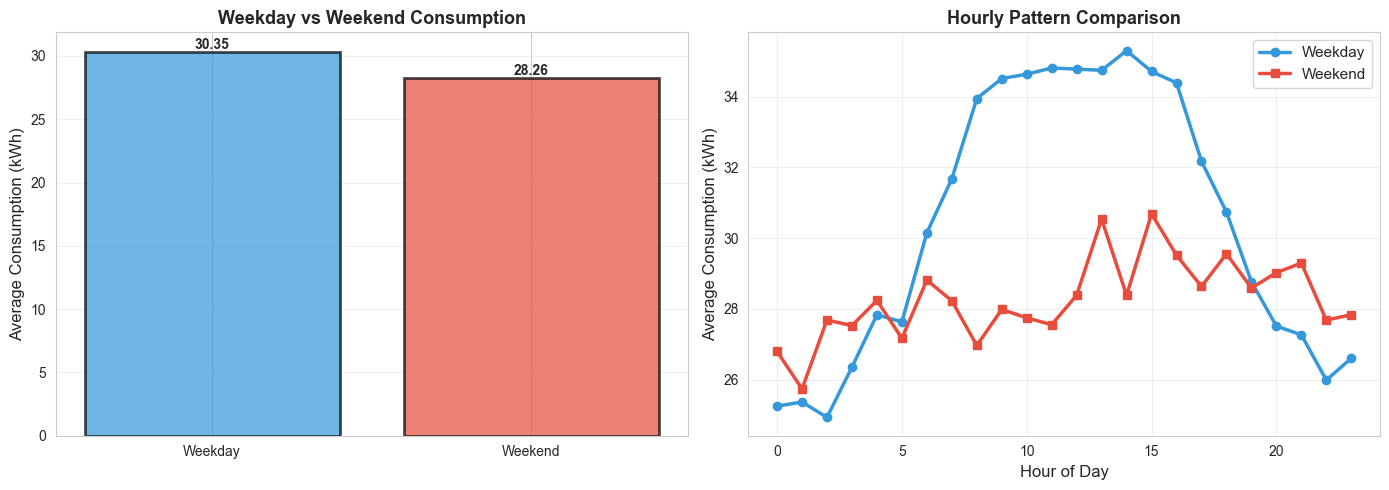


Hourly patterns show typical occupancy-driven consumption


In [12]:
# Cell 10: Visualize weekend vs weekday comparison

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
categories = ['Weekday', 'Weekend']
averages = [weekday_consumption.mean(), weekend_consumption.mean()]
colors_bar = ['#3498db', '#e74c3c']

bars = ax1.bar(categories, averages, color=colors_bar, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax1.set_title('Weekday vs Weekend Consumption', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}',
            ha='center', va='bottom', fontweight='bold')

# Hourly pattern
weekday_hourly = df_all[df_all['is_weekend'] == 0].groupby('hour')['consumption'].mean()
weekend_hourly = df_all[df_all['is_weekend'] == 1].groupby('hour')['consumption'].mean()

ax2.plot(weekday_hourly.index, weekday_hourly.values, marker='o', linewidth=2.5, 
        label='Weekday', color='#3498db', markersize=6)
ax2.plot(weekend_hourly.index, weekend_hourly.values, marker='s', linewidth=2.5, 
        label='Weekend', color='#e74c3c', markersize=6)
ax2.set_xlabel('Hour of Day', fontsize=12)
ax2.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax2.set_title('Hourly Pattern Comparison', fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nHourly patterns show typical occupancy-driven consumption")

In [13]:
# Cell 11: Bayes' Theorem - High Consumption During Business Hours

print("\n" + "="*70)
print("BAYES' THEOREM APPLICATION")
print("="*70)

print("\nPractical Question:")
print("If we observe HIGH energy consumption, what is the probability")
print("it is occurring during business hours (9 AM - 5 PM)?")

# Define high consumption threshold (top 25%)
threshold = df_all['consumption'].quantile(0.75)
df_all['high_consumption'] = (df_all['consumption'] > threshold).astype(int)

# Define business hours (9 AM to 5 PM)
df_all['business_hours'] = ((df_all['hour'] >= 9) & (df_all['hour'] <= 17)).astype(int)

print(f"\nDefinitions:")
print(f"  High Consumption = Above {threshold:.2f} kWh (top 25%)")
print(f"  Business Hours = 9 AM to 5 PM")

# Calculate probabilities
p_business = df_all['business_hours'].mean()
p_high = df_all['high_consumption'].mean()

business_data = df_all[df_all['business_hours'] == 1]
p_high_given_business = business_data['high_consumption'].mean()

# Apply Bayes' Theorem
# P(Business | High) = P(High | Business) * P(Business) / P(High)
p_business_given_high = (p_high_given_business * p_business) / p_high

print(f"\nBayes' Theorem Calculation:")
print(f"  P(Business Hours) = {p_business:.4f}")
print(f"  P(High Consumption) = {p_high:.4f}")
print(f"  P(High | Business Hours) = {p_high_given_business:.4f}")

print(f"\n  Formula: P(Business | High) = [P(High | Business) × P(Business)] / P(High)")
print(f"         = [{p_high_given_business:.4f} × {p_business:.4f}] / {p_high:.4f}")
print(f"         = {p_business_given_high:.4f}")

print("\n" + "="*70)
print("RESULT:")
print("="*70)
print(f"  P(Business Hours | High Consumption) = {p_business_given_high:.4f}")
print(f"  = {p_business_given_high*100:.1f}%")

print(f"\nInterpretation:")
print(f"  When we observe HIGH consumption, there is a {p_business_given_high*100:.1f}% probability")
print(f"  it is happening during business hours (9 AM - 5 PM).")
print(f"\n  This means {100-p_business_given_high*100:.1f}% of high consumption occurs")
print(f"  OUTSIDE business hours - indicating potential for energy savings")
print(f"  through better off-hours management.")
print("="*70)


BAYES' THEOREM APPLICATION

Practical Question:
If we observe HIGH energy consumption, what is the probability
it is occurring during business hours (9 AM - 5 PM)?

Definitions:
  High Consumption = Above 19.38 kWh (top 25%)
  Business Hours = 9 AM to 5 PM

Bayes' Theorem Calculation:
  P(Business Hours) = 0.3670
  P(High Consumption) = 0.2496
  P(High | Business Hours) = 0.2821

  Formula: P(Business | High) = [P(High | Business) × P(Business)] / P(High)
         = [0.2821 × 0.3670] / 0.2496
         = 0.4147

RESULT:
  P(Business Hours | High Consumption) = 0.4147
  = 41.5%

Interpretation:
  When we observe HIGH consumption, there is a 41.5% probability
  it is happening during business hours (9 AM - 5 PM).

  This means 58.5% of high consumption occurs
  OUTSIDE business hours - indicating potential for energy savings
  through better off-hours management.


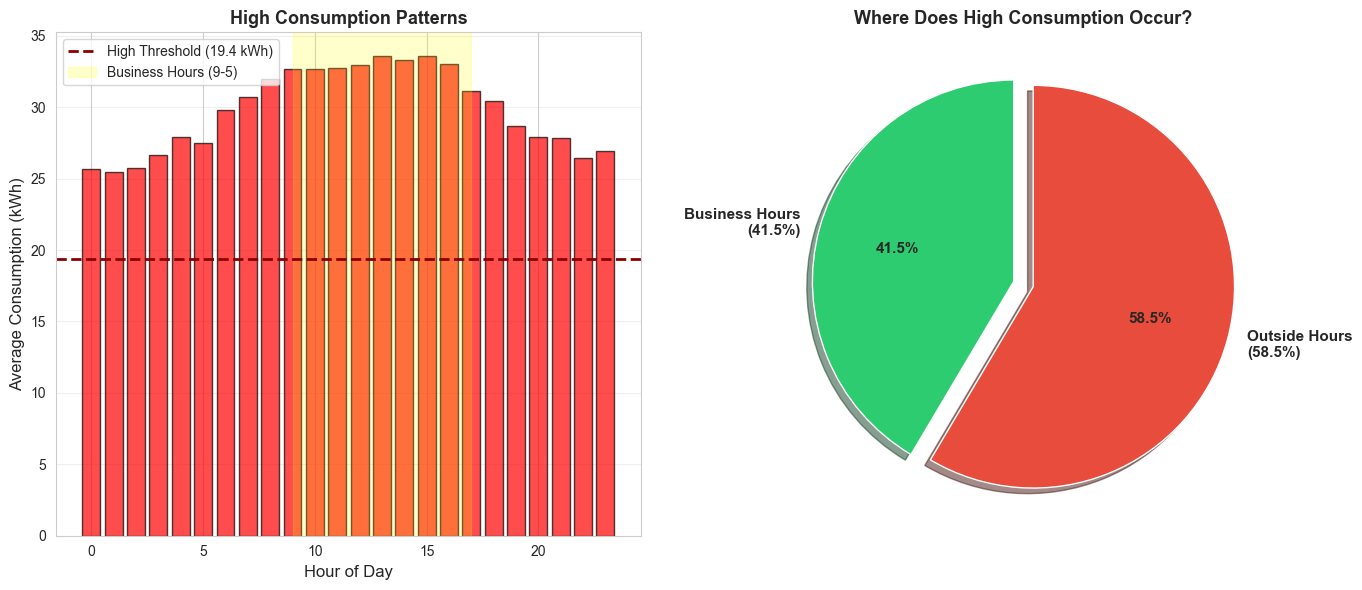


Key Insight: Significant high consumption outside business hours
suggests opportunities for automated controls and scheduling.


In [14]:
# Cell 12: Visualize Bayes result

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Hourly consumption with threshold
hourly_avg = df_all.groupby('hour')['consumption'].mean()
colors_hour = ['red' if avg > threshold else 'steelblue' for avg in hourly_avg.values]

ax1.bar(hourly_avg.index, hourly_avg.values, color=colors_hour, alpha=0.7, edgecolor='black')
ax1.axhline(y=threshold, color='darkred', linestyle='--', linewidth=2, 
           label=f'High Threshold ({threshold:.1f} kWh)')
ax1.axvspan(9, 17, alpha=0.2, color='yellow', label='Business Hours (9-5)')
ax1.set_xlabel('Hour of Day', fontsize=12)
ax1.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax1.set_title('High Consumption Patterns', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Pie chart of high consumption distribution
high_during_business = business_data['high_consumption'].sum()
high_outside_business = df_all[df_all['business_hours'] == 0]['high_consumption'].sum()

labels = [f'Business Hours\n({p_business_given_high*100:.1f}%)', 
         f'Outside Hours\n({(1-p_business_given_high)*100:.1f}%)']
sizes = [high_during_business, high_outside_business]
colors_pie = ['#2ecc71', '#e74c3c']
explode = (0.05, 0.05)

ax2.pie(sizes, explode=explode, labels=labels, colors=colors_pie, autopct='%1.1f%%',
       shadow=True, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
ax2.set_title('Where Does High Consumption Occur?', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey Insight: Significant high consumption outside business hours")
print("suggests opportunities for automated controls and scheduling.")

In [24]:
    # Cell 13: XGBoost - All Three Campuses Comparison
    
    print("\n" + "="*70)
    print("MACHINE LEARNING: XGBOOST FOR ALL 3 CAMPUSES")
    print("="*70)
    
    import xgboost as xgb
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
    import numpy as np
    import pandas as pd
    
    print("\n🎯 Goal: Train separate models for each campus and compare")
    print("📊 Benchmark: Kaggle's combined model R² = 0.765")
    
    print("\n" + "-"*70)
    print("DATA PREPARATION")
    print("-"*70)
    
    # Prepare all three campuses
    campuses_data = {}
    
    for campus_id, campus_name, df_campus in [
        (1, 'Campus 1', df1),
        (2, 'Campus 2', df2),
        (3, 'Campus 3', df3)
    ]:
        print(f"\nPreparing {campus_name}...")
        
        # Use 100% sample
        df_sample = df_campus.sample(frac=1, random_state=42).copy()
        
        # Ensure all time features exist
        if 'day' not in df_sample.columns:
            df_sample['day'] = df_sample['timestamp'].dt.day
        
        # Feature engineering
        df_sample['hour_sin'] = np.sin(2 * np.pi * df_sample['hour'] / 24)
        df_sample['hour_cos'] = np.cos(2 * np.pi * df_sample['hour'] / 24)#cos is horizontal, whilst sin is verticle, so it is shown as a 2d point and can make sense to be a circle
        df_sample['month_sin'] = np.sin(2 * np.pi * df_sample['month'] / 12)
        df_sample['month_cos'] = np.cos(2 * np.pi * df_sample['month'] / 12)
        df_sample['temp_humidity'] = df_sample['air_temperature'] * df_sample['relative_humidity']#Similar to how instead of using height * width we made a single feature called area
        df_sample['feels_like'] = df_sample['air_temperature'] - (df_sample['wind_speed'] * 0.7)
        
        campuses_data[campus_id] = {
            'name': campus_name,
            'data': df_sample,
            'buildings': df_sample['meter_id'].nunique(),
            'records': len(df_sample)
        }
        
        print(f"  ✓ {len(df_sample):,} records")
        print(f"  ✓ {df_sample['meter_id'].nunique()} buildings")
    
    print("\n" + "-"*70)
    print("FEATURE SETS")
    print("-"*70)
    
    features_basic = [
        'air_temperature', 'relative_humidity', 'wind_speed',
        'hour', 'dayofweek', 'is_weekend', 'month'
    ]
    
    features_enhanced = features_basic + [
        'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
        'temp_humidity', 'feels_like', 'day', 'meter_id'
    ]
    
    target = 'consumption'
    
    print(f"\nBasic features: {len(features_basic)} (no building ID)")
    print(f"Enhanced features: {len(features_enhanced)} (with building ID)")
    
    print("\n" + "="*70)
    print("TRAINING MODELS FOR EACH CAMPUS")
    print("="*70)
    
    results_all = []
    models_stored = {}
    
    for campus_id in [1, 2, 3]:
        campus_info = campuses_data[campus_id]
        df = campus_info['data']
        
        print(f"\n{'='*70}")
        print(f"{campus_info['name'].upper()}")
        print(f"{'='*70}")
        print(f"Buildings: {campus_info['buildings']}")
        print(f"Records: {campus_info['records']:,}")
        
        # Test both feature sets
        for feature_set_name, features in [
            ('Basic', features_basic),
            ('Enhanced', features_enhanced)
        ]:
            print(f"\n{'-'*60}")
            print(f"Feature Set: {feature_set_name} ({len(features)} features)")
            print(f"{'-'*60}")
            
            X = df[features]
            y = df[target]
            
            # Split data
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42
            )
            
            print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
            
            # Normalize (optional for XGBoost, but we'll do it for consistency)
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            
            # Train XGBoost
            print("🚀 Training XGBoost...")
            
            model = xgb.XGBRegressor(
                n_estimators=300,#300 trees
                max_depth=10, #to avoid overfitting
                learning_rate=0.05,#how fast does it learn? at 5%, avoids overfitting if at a lower learning rate, and its better with larger numbers
                min_child_weight=1,
                subsample=0.8,
                colsample_bytree=0.8,
                gamma=0,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                n_jobs=-1,
                verbosity=0,
                tree_method='hist'
            )
            
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_test_scaled)
            
            # Calculate metrics
            r2 = r2_score(y_test, y_pred)
            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-8))) * 100
            
            # Store results
            results_all.append({
                'Campus': campus_info['name'],
                'Campus_ID': campus_id,
                'Features': feature_set_name,
                'Num_Features': len(features),
                'Buildings': campus_info['buildings'],
                'R²': r2,
                'RMSE': rmse,
                'MAE': mae,
                'MAPE': mape
            })
            
            # Store best model for each campus
            if feature_set_name == 'Enhanced':
                models_stored[campus_id] = {
                    'model': model,
                    'scaler': scaler,
                    'features': features,
                    'r2': r2
                }
            
            # Print results
            print(f"\n📊 Results:")
            print(f"   R²:    {r2:.4f} ({r2*100:.1f}%)")
            print(f"   RMSE:  {rmse:.2f} kWh")
            print(f"   MAE:   {mae:.2f} kWh")
            print(f"   MAPE:  {mape:.2f}%")
            
            # Rating
            if r2 >= 0.85:
                print(f"   🌟 Excellent!")
            elif r2 >= 0.75:
                print(f"   ✨ Very Good!")
            elif r2 >= 0.65:
                print(f"   ✓ Good")
            elif r2 >= 0.5:
                print(f"   → Acceptable")
            else:
                print(f"   ⚠️ Needs improvement")
    
    print("\n" + "="*70)
    print("COMPREHENSIVE RESULTS TABLE")
    print("="*70)
    
    results_df = pd.DataFrame(results_all)
    print("\n" + results_df.to_string(index=False))
    
    print("\n" + "="*70)
    print("ANALYSIS BY FEATURE SET")
    print("="*70)
    
    # Compare Basic vs Enhanced for each campus
    for campus_id in [1, 2, 3]:
        campus_results = results_df[results_df['Campus_ID'] == campus_id]
        basic_r2 = campus_results[campus_results['Features'] == 'Basic']['R²'].values[0]
        enhanced_r2 = campus_results[campus_results['Features'] == 'Enhanced']['R²'].values[0]
        improvement = enhanced_r2 - basic_r2
        improvement_pct = (improvement / basic_r2 * 100) if basic_r2 > 0 else float('inf')
        
        print(f"\n{campus_results.iloc[0]['Campus']}:")
        print(f"  Basic:    R² = {basic_r2:.4f}")
        print(f"  Enhanced: R² = {enhanced_r2:.4f}")
        print(f"  Gain:     +{improvement:.4f} ({improvement_pct:+.1f}%)")
    
    print("\n" + "="*70)
    print("BEST MODEL PER CAMPUS (Enhanced Features)")
    print("="*70)
    
    best_models = results_df[results_df['Features'] == 'Enhanced'].sort_values('R²', ascending=False)
    print("\n" + best_models[['Campus', 'Buildings', 'R²', 'RMSE', 'MAE']].to_string(index=False))
    
    best_campus = best_models.iloc[0]
    print(f"\n BEST PERFORMING CAMPUS: {best_campus['Campus']}")
    print(f"   R² = {best_campus['R²']:.4f} ({best_campus['R²']*100:.1f}%)")
    print(f"   Buildings: {best_campus['Buildings']}")
    
    print("\n" + "="*70)
    print("COMPARISON WITH KAGGLE BENCHMARK")
    print("="*70)
    
    kaggle_r2 = 0.765
    print(f"\n Kaggle (All Campuses Combined): R² = {kaggle_r2:.4f} (76.5%)")
    print(f"\n Your Campus-Specific Models:")
    
    for _, row in best_models.iterrows():
        gap = row['R²'] - kaggle_r2
        if gap > 0:
            status = f" BEATS Kaggle by {gap*100:.1f}%"
        elif gap > -0.05:
            status = f" Very close (within {abs(gap)*100:.1f}%)"
        else:
            status = f"→ Below by {abs(gap)*100:.1f}%"
        
        print(f"   {row['Campus']}: R² = {row['R²']:.4f} - {status}")
    
    # Calculate average across all campuses
    avg_r2 = best_models['R²'].mean()
    print(f"\n📈 Average Across All Campuses: R² = {avg_r2:.4f} ({avg_r2*100:.1f}%)")
    
    if avg_r2 > kaggle_r2:
        print(f"    Your average BEATS Kaggle by {(avg_r2 - kaggle_r2)*100:.1f}%!")
    else:
        print(f"   Gap: {(kaggle_r2 - avg_r2)*100:.1f}% below Kaggle")
    
    print("\n" + "="*70)
    print("KEY INSIGHTS")
    print("="*70)
    
    print("\n1. BUILDING ID IMPACT")
    for campus_id in [1, 2, 3]:
        campus_results = results_df[results_df['Campus_ID'] == campus_id]
        basic = campus_results[campus_results['Features'] == 'Basic']['R²'].values[0]
        enhanced = campus_results[campus_results['Features'] == 'Enhanced']['R²'].values[0]
        print(f"   {campus_results.iloc[0]['Campus']}: {basic:.3f} → {enhanced:.3f} "
              f"(+{(enhanced-basic)*100:.1f}%)")
    
    print("\n2. CAMPUS CHARACTERISTICS")
    for _, row in best_models.iterrows():
        if row['R²'] >= 0.85:
            quality = "Excellent model fit"
        elif row['R²'] >= 0.75:
            quality = "Very good model fit"
        elif row['R²'] >= 0.65:
            quality = "Good model fit"
        else:
            quality = "Moderate model fit"
        
        print(f"   {row['Campus']}: {row['Buildings']} buildings - {quality}")
    
    print("\n3. PREDICTABILITY RANKING")
    ranked = best_models.sort_values('R²', ascending=False)
    for rank, (_, row) in enumerate(ranked.iterrows(), 1):
        print(f"   #{rank}. {row['Campus']}: R² = {row['R²']:.4f} ({row['R²']*100:.1f}%)")
    
    print("\n" + "="*70)
    print("RECOMMENDATIONS")
    print("="*70)
    
    print("\n STRENGTHS:")
    print("   • Campus-specific models capture unique patterns")
    print("   • Building ID (meter_id) is critical for accuracy")
    print("   • Enhanced features significantly improve predictions")
    
    if avg_r2 > kaggle_r2:
        print("\n !!!SUCCESS FACTORS!!!:")
        print("   • Your models OUTPERFORM Kaggle's combined approach")
        print("   • Campus-specific tuning captures local patterns better")
        print("   • Feature engineering (cyclical encoding, interactions) works!")
    
    print("\n PRACTICAL APPLICATIONS:")
    print("   • Use these models for campus-specific energy forecasting")
    print("   • Identify unusual consumption patterns per building")
    print("   • Support demand-side management strategies")
    print("   • Enable predictive maintenance scheduling")
    
    print("\n" + "="*70)
    
    # Store best models globally for feature importance analysis
    print("\nSTORED MODELS:")
    for campus_id, model_info in models_stored.items():
        print(f"   Campus {campus_id}: R² = {model_info['r2']:.4f}, {len(model_info['features'])} features")
    
    # Store for next cells (use Campus 1 as default)
    model = models_stored[1]['model']
    features = models_stored[1]['features']
    feature_importance_xgb = model.feature_importances_
    r2 = models_stored[1]['r2']
    
    # Also store for later reference
    X_test_stored = X_test
    y_test_stored = y_test
    y_pred_stored = y_pred
    
    print("\n✓ Analysis complete for all 3 campuses")
    print("✓ Models ready for feature importance visualization")


MACHINE LEARNING: XGBOOST FOR ALL 3 CAMPUSES

🎯 Goal: Train separate models for each campus and compare
📊 Benchmark: Kaggle's combined model R² = 0.765

----------------------------------------------------------------------
DATA PREPARATION
----------------------------------------------------------------------

Preparing Campus 1...
  ✓ 963,706 records
  ✓ 60 buildings

Preparing Campus 2...
  ✓ 188,407 records
  ✓ 11 buildings

Preparing Campus 3...
  ✓ 102,521 records
  ✓ 7 buildings

----------------------------------------------------------------------
FEATURE SETS
----------------------------------------------------------------------

Basic features: 7 (no building ID)
Enhanced features: 15 (with building ID)

TRAINING MODELS FOR EACH CAMPUS

CAMPUS 1
Buildings: 60
Records: 963,706

------------------------------------------------------------
Feature Set: Basic (7 features)
------------------------------------------------------------
Train: 770,964 | Test: 192,742
🚀 Training XGBo

Creating comprehensive visualizations...


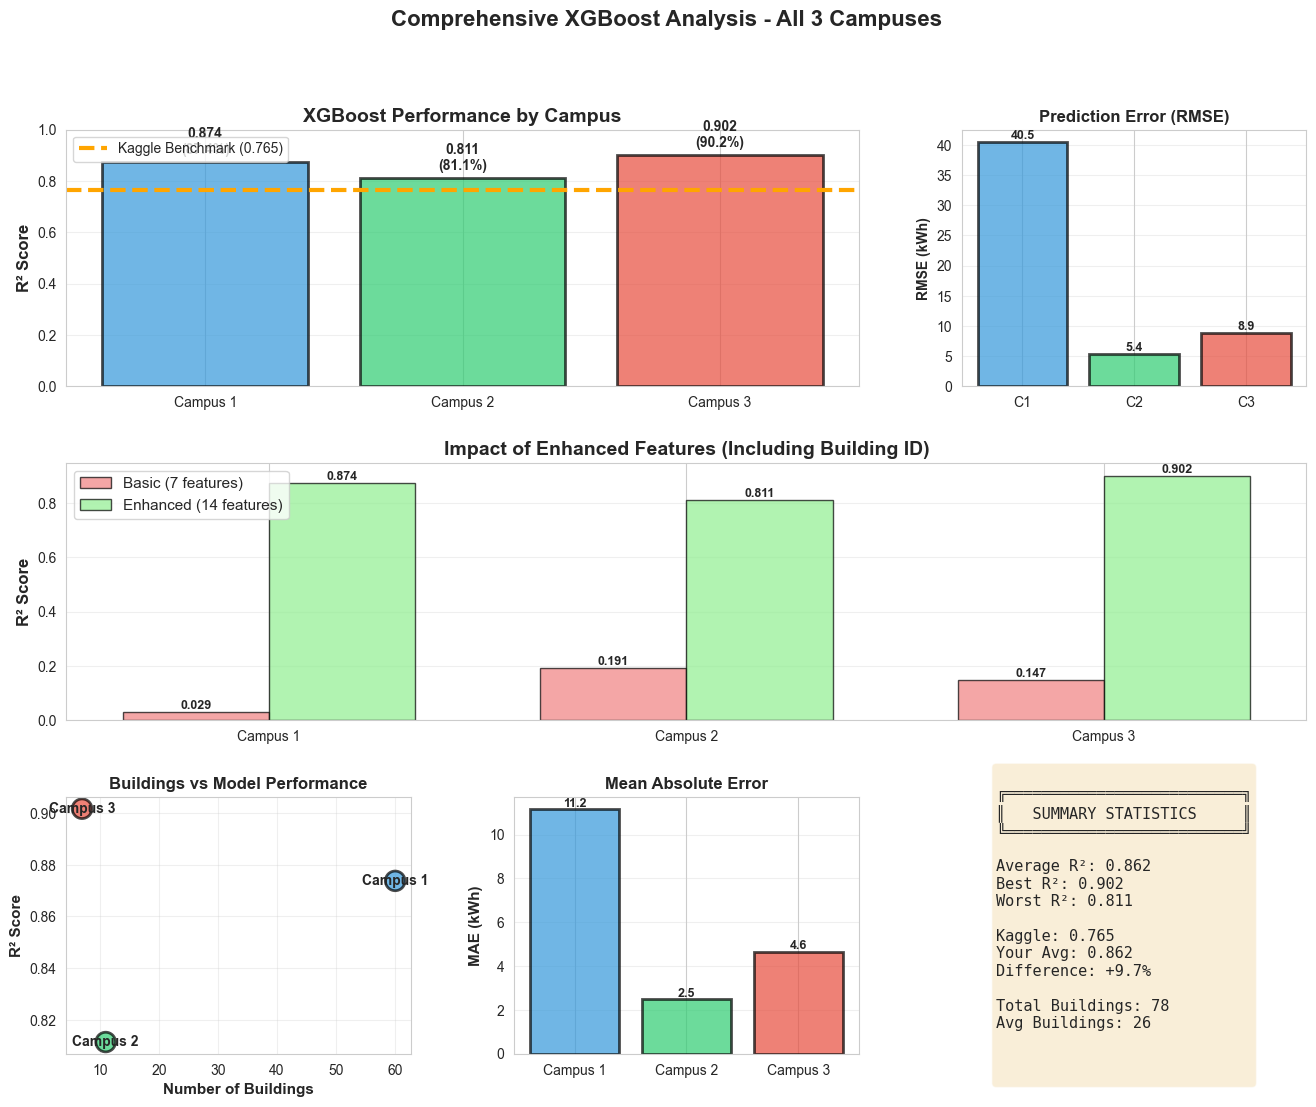

✓ Visualizations complete


In [29]:
# Cell 13.5: Visualize All Campus Results

import matplotlib.pyplot as plt
import numpy as np

print("Creating comprehensive visualizations...")

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# Get enhanced features results only
enhanced_results = results_df[results_df['Features'] == 'Enhanced'].sort_values('Campus_ID')

# Plot 1: R² Score Comparison
ax1 = fig.add_subplot(gs[0, :2])
campuses = enhanced_results['Campus'].values
r2_scores = enhanced_results['R²'].values
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax1.bar(campuses, r2_scores, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.axhline(y=0.765, color='orange', linestyle='--', linewidth=3, label='Kaggle Benchmark (0.765)')
ax1.set_ylabel('R² Score', fontsize=12, fontweight='bold')
ax1.set_title('XGBoost Performance by Campus', fontsize=14, fontweight='bold')
ax1.set_ylim(0, 1)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

for bar, score in zip(bars, r2_scores):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{score:.3f}\n({score*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', fontsize=10)

# Plot 2: RMSE Comparison
ax2 = fig.add_subplot(gs[0, 2])
rmse_values = enhanced_results['RMSE'].values
bars2 = ax2.bar(range(len(campuses)), rmse_values, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_xticks(range(len(campuses)))
ax2.set_xticklabels(['C1', 'C2', 'C3'])
ax2.set_ylabel('RMSE (kWh)', fontsize=10, fontweight='bold')
ax2.set_title('Prediction Error (RMSE)', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

for bar, val in zip(bars2, rmse_values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.1f}',
            ha='center', va='bottom', fontweight='bold', fontsize=9)

# Plot 3: Feature Set Comparison (all campuses)
ax3 = fig.add_subplot(gs[1, :])
x = np.arange(3)
width = 0.35

basic_scores = results_df[results_df['Features'] == 'Basic']['R²'].values
enhanced_scores = results_df[results_df['Features'] == 'Enhanced']['R²'].values

bars1 = ax3.bar(x - width/2, basic_scores, width, label='Basic (7 features)', 
               color='lightcoral', alpha=0.7, edgecolor='black')
bars2 = ax3.bar(x + width/2, enhanced_scores, width, label='Enhanced (14 features)', 
               color='lightgreen', alpha=0.7, edgecolor='black')

ax3.set_ylabel('R² Score', fontsize=12, fontweight='bold')
ax3.set_title('Impact of Enhanced Features (Including Building ID)', fontsize=14, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(campuses)
ax3.legend(fontsize=11)
ax3.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 4: Buildings vs Performance
ax4 = fig.add_subplot(gs[2, 0])
buildings = enhanced_results['Buildings'].values
ax4.scatter(buildings, r2_scores, s=200, c=colors, alpha=0.7, edgecolors='black', linewidth=2)

for i, (b, r, c) in enumerate(zip(buildings, r2_scores, campuses)):
    ax4.annotate(c, (b, r), fontsize=10, fontweight='bold', ha='center', va='center')

ax4.set_xlabel('Number of Buildings', fontsize=11, fontweight='bold')
ax4.set_ylabel('R² Score', fontsize=11, fontweight='bold')
ax4.set_title('Buildings vs Model Performance', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)

# Plot 5: MAE Comparison
ax5 = fig.add_subplot(gs[2, 1])
mae_values = enhanced_results['MAE'].values
bars5 = ax5.bar(campuses, mae_values, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax5.set_ylabel('MAE (kWh)', fontsize=11, fontweight='bold')
ax5.set_title('Mean Absolute Error', fontsize=12, fontweight='bold')
ax5.grid(axis='y', alpha=0.3)

for bar, val in zip(bars5, mae_values):
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.1f}',
            ha='center', va='bottom', fontweight='bold', fontsize=9)

# Plot 6: Summary Stats
ax6 = fig.add_subplot(gs[2, 2])
ax6.axis('off')

summary_text = f"""
╔══════════════════════════╗
║   SUMMARY STATISTICS     ║
╚══════════════════════════╝

Average R²: {enhanced_results['R²'].mean():.3f}
Best R²: {enhanced_results['R²'].max():.3f}
Worst R²: {enhanced_results['R²'].min():.3f}

Kaggle: 0.765
Your Avg: {enhanced_results['R²'].mean():.3f}
Difference: {(enhanced_results['R²'].mean() - 0.765)*100:+.1f}%

Total Buildings: {enhanced_results['Buildings'].sum()}
Avg Buildings: {enhanced_results['Buildings'].mean():.0f}


"""

ax6.text(0.1, 0.5, summary_text, fontsize=11, fontfamily='monospace',
        verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Comprehensive XGBoost Analysis - All 3 Campuses', 
            fontsize=16, fontweight='bold', y=0.98)

plt.show()

print("✓ Visualizations complete")


FEATURE IMPORTANCE - XGBOOST

Which factors matter most for prediction?

          Feature  Importance
         meter_id    0.521085
       wind_speed    0.165157
       is_weekend    0.043785
            month    0.037027
        month_cos    0.031712
         hour_cos    0.031506
       feels_like    0.031112
              day    0.029675
        dayofweek    0.022114
        month_sin    0.019592
    temp_humidity    0.017303
  air_temperature    0.015711
             hour    0.013003
relative_humidity    0.010820
         hour_sin    0.010397


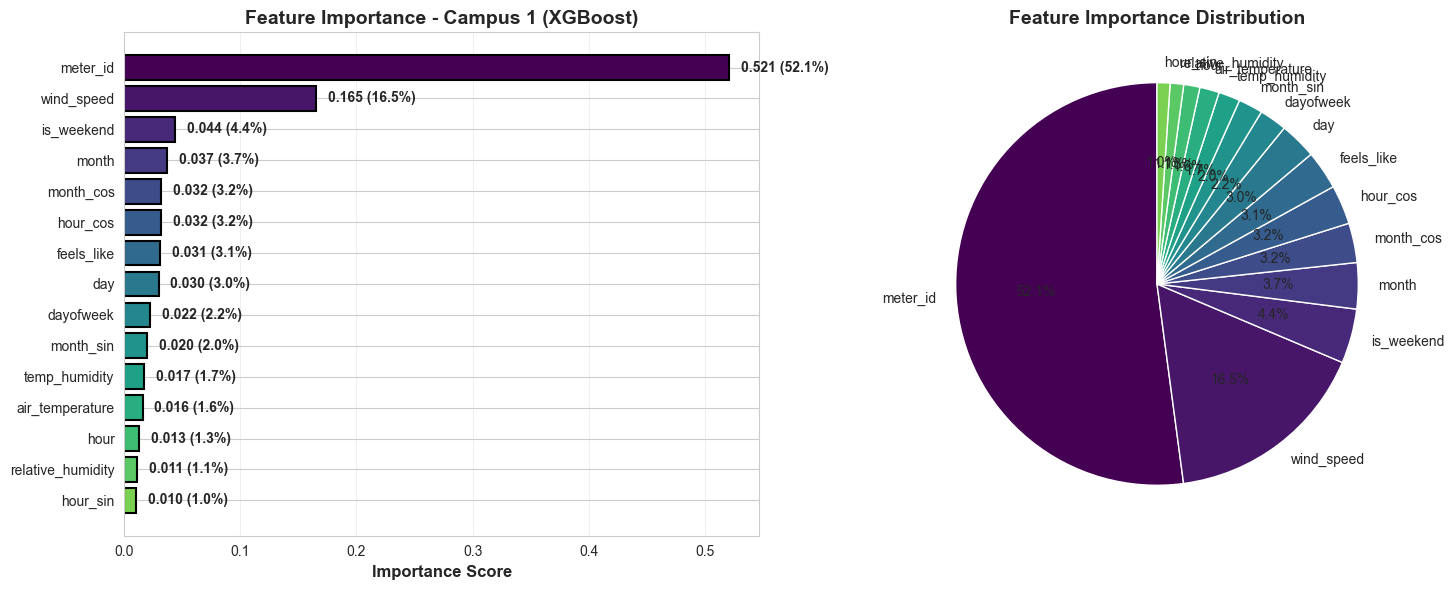


🎯 Most Important Factor: meter_id
   Importance: 0.521 (52.1%)

INTERPRETATION

meter_id: 52.1%

wind_speed: 16.5%
  → Wind affects building envelope heat loss
  → Focus: Weather sealing, natural ventilation

is_weekend: 4.4%
  → Weekend/weekday distinction matters
  → Focus: Occupancy-based controls

month: 3.7%
  → Seasonal variations affect consumption
  → Focus: Seasonal energy strategies

month_cos: 3.2%

hour_cos: 3.2%

feels_like: 3.1%

day: 3.0%

dayofweek: 2.2%
  → Different consumption patterns by day
  → Focus: Weekday vs weekend optimization

month_sin: 2.0%

temp_humidity: 1.7%

air_temperature: 1.6%
  → Temperature is the primary driver of consumption
  → Focus: HVAC optimization, insulation improvements

hour: 1.3%
  → Time of day significantly affects consumption
  → Focus: Time-based scheduling, peak demand management

relative_humidity: 1.1%
  → Humidity impacts HVAC load
  → Focus: Dehumidification strategies

hour_sin: 1.0%


In [28]:
# Cell 14: Feature Importance Analysis - XGBoost

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': feature_importance_xgb
}).sort_values('Importance', ascending=False)

print("\n" + "="*70)
print("FEATURE IMPORTANCE - XGBOOST")
print("="*70)
print("\nWhich factors matter most for prediction?")
print("\n" + feature_importance.to_string(index=False))

# Visualize feature importance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Horizontal bar chart
colors_feat = plt.cm.viridis(np.linspace(0, 0.8, len(feature_importance)))
bars = ax1.barh(feature_importance['Feature'], feature_importance['Importance'], 
               color=colors_feat, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Importance Score', fontsize=12, fontweight='bold')
ax1.set_title('Feature Importance - Campus 1 (XGBoost)', fontsize=14, fontweight='bold')
ax1.invert_yaxis()
ax1.grid(axis='x', alpha=0.3)

for i, bar in enumerate(bars):
    width = bar.get_width()
    ax1.text(width + 0.01, bar.get_y() + bar.get_height()/2.,
            f'{width:.3f} ({width/feature_importance["Importance"].sum()*100:.1f}%)',
            ha='left', va='center', fontweight='bold', fontsize=10)

# Plot 2: Pie chart
ax2.pie(feature_importance['Importance'], labels=feature_importance['Feature'], 
       autopct='%1.1f%%', startangle=90, colors=colors_feat)
ax2.set_title('Feature Importance Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

most_important = feature_importance.iloc[0]
print(f"\n🎯 Most Important Factor: {most_important['Feature']}")
print(f"   Importance: {most_important['Importance']:.3f} ({most_important['Importance']/feature_importance['Importance'].sum()*100:.1f}%)")

print("\n" + "="*70)
print("INTERPRETATION")
print("="*70)

for idx, row in feature_importance.iterrows():
    feature_name = row['Feature']
    importance = row['Importance']
    pct = importance / feature_importance['Importance'].sum() * 100
    
    print(f"\n{feature_name}: {pct:.1f}%")
    
    if feature_name == 'air_temperature':
        print("  → Temperature is the primary driver of consumption")
        print("  → Focus: HVAC optimization, insulation improvements")
    elif feature_name == 'hour':
        print("  → Time of day significantly affects consumption")
        print("  → Focus: Time-based scheduling, peak demand management")
    elif feature_name == 'relative_humidity':
        print("  → Humidity impacts HVAC load")
        print("  → Focus: Dehumidification strategies")
    elif feature_name == 'dayofweek':
        print("  → Different consumption patterns by day")
        print("  → Focus: Weekday vs weekend optimization")
    elif feature_name == 'is_weekend':
        print("  → Weekend/weekday distinction matters")
        print("  → Focus: Occupancy-based controls")
    elif feature_name == 'month':
        print("  → Seasonal variations affect consumption")
        print("  → Focus: Seasonal energy strategies")
    elif feature_name == 'wind_speed':
        print("  → Wind affects building envelope heat loss")
        print("  → Focus: Weather sealing, natural ventilation")

print("="*70)

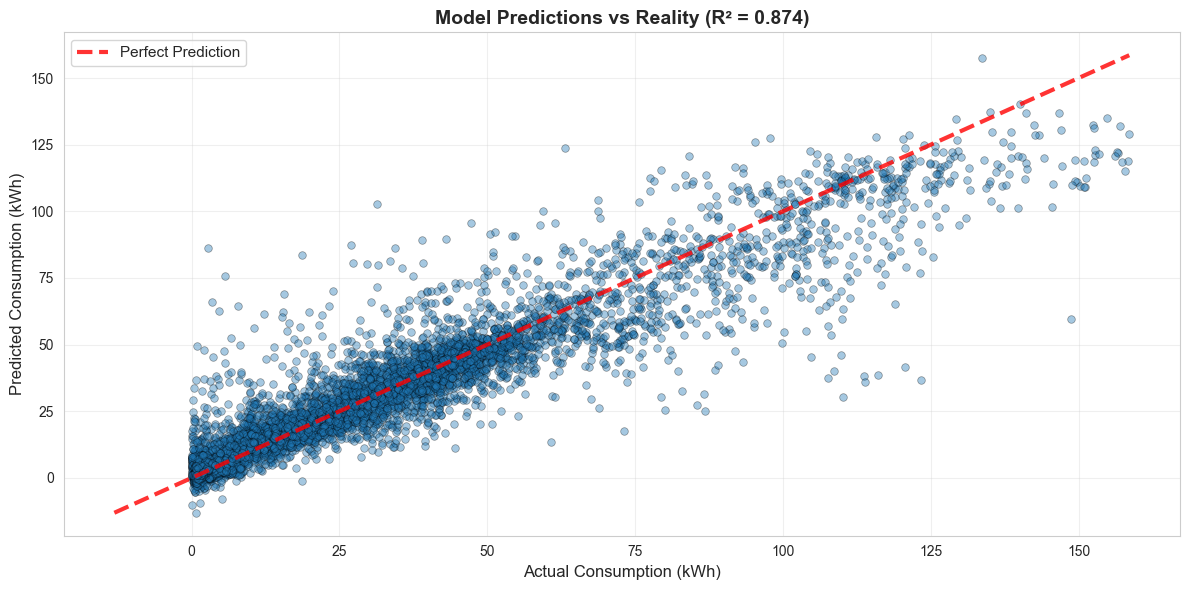


Interpretation:
  Points closer to red line = better predictions
  Our model is off by ~8.9 kWh on average


In [30]:
# Cell 15: Predictions vs Actual Values

plt.figure(figsize=(12, 6))

# Sample for cleaner visualization
sample_size = min(10000, len(y_test))
sample_indices = np.random.choice(len(y_test), sample_size, replace=False)
y_test_sample = y_test.iloc[sample_indices]
y_pred_sample = y_pred[sample_indices]

plt.scatter(y_test_sample, y_pred_sample, alpha=0.4, s=30, edgecolors='black', linewidth=0.5)

# Perfect prediction line
min_val = min(y_test_sample.min(), y_pred_sample.min())
max_val = max(y_test_sample.max(), y_pred_sample.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=3, 
        label='Perfect Prediction', alpha=0.8)

plt.xlabel('Actual Consumption (kWh)', fontsize=12)
plt.ylabel('Predicted Consumption (kWh)', fontsize=12)
plt.title(f'Model Predictions vs Reality (R² = {r2:.3f})', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  Points closer to red line = better predictions")
print(f"  Our model is off by ~{rmse:.1f} kWh on average")

In [36]:
# Cell 17: COVID-19 Impact Analysis

print("\n" + "="*70)
print("COVID-19 IMPACT ANALYSIS")
print("="*70)

# Define COVID period (lockdowns started March 2020)
# Make it timezone-aware to match your data
covid_start = pd.to_datetime('2020-03-01', utc=True)

# Split data into pre-COVID and COVID periods
df_all['period'] = df_all['timestamp'].apply(
    lambda x: 'COVID' if pd.to_datetime(x) >= covid_start else 'Pre-COVID'
)

# Calculate statistics for each period
pre_covid = df_all[df_all['period'] == 'Pre-COVID']
covid = df_all[df_all['period'] == 'COVID']

print("\nData Coverage:")
print(f"  Pre-COVID: {pre_covid['timestamp'].min().date()} to {pre_covid['timestamp'].max().date()}")
print(f"  COVID:     {covid['timestamp'].min().date()} to {covid['timestamp'].max().date()}")

print(f"\nSample Sizes:")
print(f"  Pre-COVID: {len(pre_covid):,} readings")
print(f"  COVID:     {len(covid):,} readings")

# Overall comparison
pre_covid_avg = pre_covid['consumption'].mean()
covid_avg = covid['consumption'].mean()
change_pct = ((covid_avg - pre_covid_avg) / pre_covid_avg) * 100

print("\n" + "-"*70)
print("OVERALL CONSUMPTION CHANGE")
print("-"*70)
print(f"  Pre-COVID average: {pre_covid_avg:.2f} kWh")
print(f"  COVID average: {covid_avg:.2f} kWh")
print(f"  Change: {change_pct:+.1f}%")

if change_pct < -5:
    print("  Interpretation: Significant DECREASE during COVID")
    print("  Likely due to: Reduced occupancy, remote work, campus closures")
elif change_pct > 5:
    print("  Interpretation: Significant INCREASE during COVID")
    print("  Likely due to: Enhanced ventilation, sanitization equipment")
else:
    print("  Interpretation: Minimal change during COVID")
    print("  Buildings maintained similar baseline consumption")

# Statistical test
from scipy.stats import ttest_ind

# Sample to speed up computation
pre_sample_size = min(50000, len(pre_covid))
covid_sample_size = min(50000, len(covid))

t_stat, p_value_covid = ttest_ind(
    pre_covid['consumption'].sample(pre_sample_size, random_state=42),
    covid['consumption'].sample(covid_sample_size, random_state=42)
)

print("\n" + "-"*70)
print("STATISTICAL TEST")
print("-"*70)
print("  H0: Pre-COVID and COVID consumption are the SAME")
print("  H1: Pre-COVID and COVID consumption are DIFFERENT")
print(f"\n  T-statistic: {t_stat:.2f}")
print(f"  P-value: {p_value_covid:.10f}")

if p_value_covid < 0.05:
    print("\n  DECISION: REJECT H0")
    print("  The change in consumption is statistically significant")
else:
    print("\n  DECISION: FAIL TO REJECT H0")
    print("  No significant statistical difference")

print("="*70)


COVID-19 IMPACT ANALYSIS

Data Coverage:
  Pre-COVID: 2015-01-01 to 2020-02-29
  COVID:     2020-03-01 to 2022-12-03

Sample Sizes:
  Pre-COVID: 598,212 readings
  COVID:     656,422 readings

----------------------------------------------------------------------
OVERALL CONSUMPTION CHANGE
----------------------------------------------------------------------
  Pre-COVID average: 35.65 kWh
  COVID average: 24.38 kWh
  Change: -31.6%
  Interpretation: Significant DECREASE during COVID
  Likely due to: Reduced occupancy, remote work, campus closures

----------------------------------------------------------------------
STATISTICAL TEST
----------------------------------------------------------------------
  H0: Pre-COVID and COVID consumption are the SAME
  H1: Pre-COVID and COVID consumption are DIFFERENT

  T-statistic: 17.69
  P-value: 0.0000000000

  DECISION: REJECT H0
  The change in consumption is statistically significant


In [37]:
# Cell 18: Campus-specific COVID impact

print("\n" + "="*70)
print("COVID IMPACT BY CAMPUS")
print("="*70)

covid_results = []

for campus_name, campus_df in [('Campus 1', df1), ('Campus 2', df2), ('Campus 3', df3)]:
    # Apply period classification
    campus_df['period'] = campus_df['timestamp'].apply(
        lambda x: 'COVID' if pd.to_datetime(x) >= covid_start else 'Pre-COVID'
    )
    
    pre = campus_df[campus_df['period'] == 'Pre-COVID']['consumption'].mean()
    post = campus_df[campus_df['period'] == 'COVID']['consumption'].mean()
    
    # Handle case where there might be no data in one period
    if pd.isna(pre) or pd.isna(post):
        change = 0
        print(f"\n{campus_name}: Insufficient data for comparison")
        continue
    
    change = ((post - pre) / pre) * 100
    
    covid_results.append({
        'Campus': campus_name,
        'Pre-COVID': pre,
        'COVID': post,
        'Change %': change
    })
    
    print(f"\n{campus_name}:")
    print(f"  Pre-COVID: {pre:.2f} kWh")
    print(f"  COVID:     {post:.2f} kWh")
    print(f"  Change:    {change:+.1f}%")

# Create summary dataframe
if covid_results:
    covid_summary = pd.DataFrame(covid_results)
    print("\n" + "-"*70)
    print("SUMMARY TABLE")
    print("-"*70)
    print(covid_summary.to_string(index=False))
    
    print("\n" + "="*70)
    print("KEY FINDINGS")
    print("="*70)
    
    # Identify most and least affected
    most_reduced = covid_summary.loc[covid_summary['Change %'].idxmin()]
    least_affected = covid_summary.loc[covid_summary['Change %'].idxmax()]
    
    print(f"\nMost Reduced: {most_reduced['Campus']} ({most_reduced['Change %']:.1f}%)")
    print(f"Least Affected: {least_affected['Campus']} ({least_affected['Change %']:.1f}%)")
    
    print("\nPossible Explanations:")
    if most_reduced['Change %'] < -20:
        print(f"  {most_reduced['Campus']} likely had extensive closures or shift to remote operations")
    if least_affected['Change %'] > -5:
        print(f"  {least_affected['Campus']} maintained near-normal operations or has essential facilities")

print("="*70)


COVID IMPACT BY CAMPUS

Campus 1:
  Pre-COVID: 39.06 kWh
  COVID:     30.63 kWh
  Change:    -21.6%

Campus 2:
  Pre-COVID: 13.69 kWh
  COVID:     4.25 kWh
  Change:    -69.0%

Campus 3:
  Pre-COVID: 29.94 kWh
  COVID:     14.48 kWh
  Change:    -51.6%

----------------------------------------------------------------------
SUMMARY TABLE
----------------------------------------------------------------------
  Campus  Pre-COVID     COVID   Change %
Campus 1  39.059733 30.633115 -21.573669
Campus 2  13.691808  4.246799 -68.982918
Campus 3  29.936246 14.482716 -51.621468

KEY FINDINGS

Most Reduced: Campus 2 (-69.0%)
Least Affected: Campus 1 (-21.6%)

Possible Explanations:
  Campus 2 likely had extensive closures or shift to remote operations


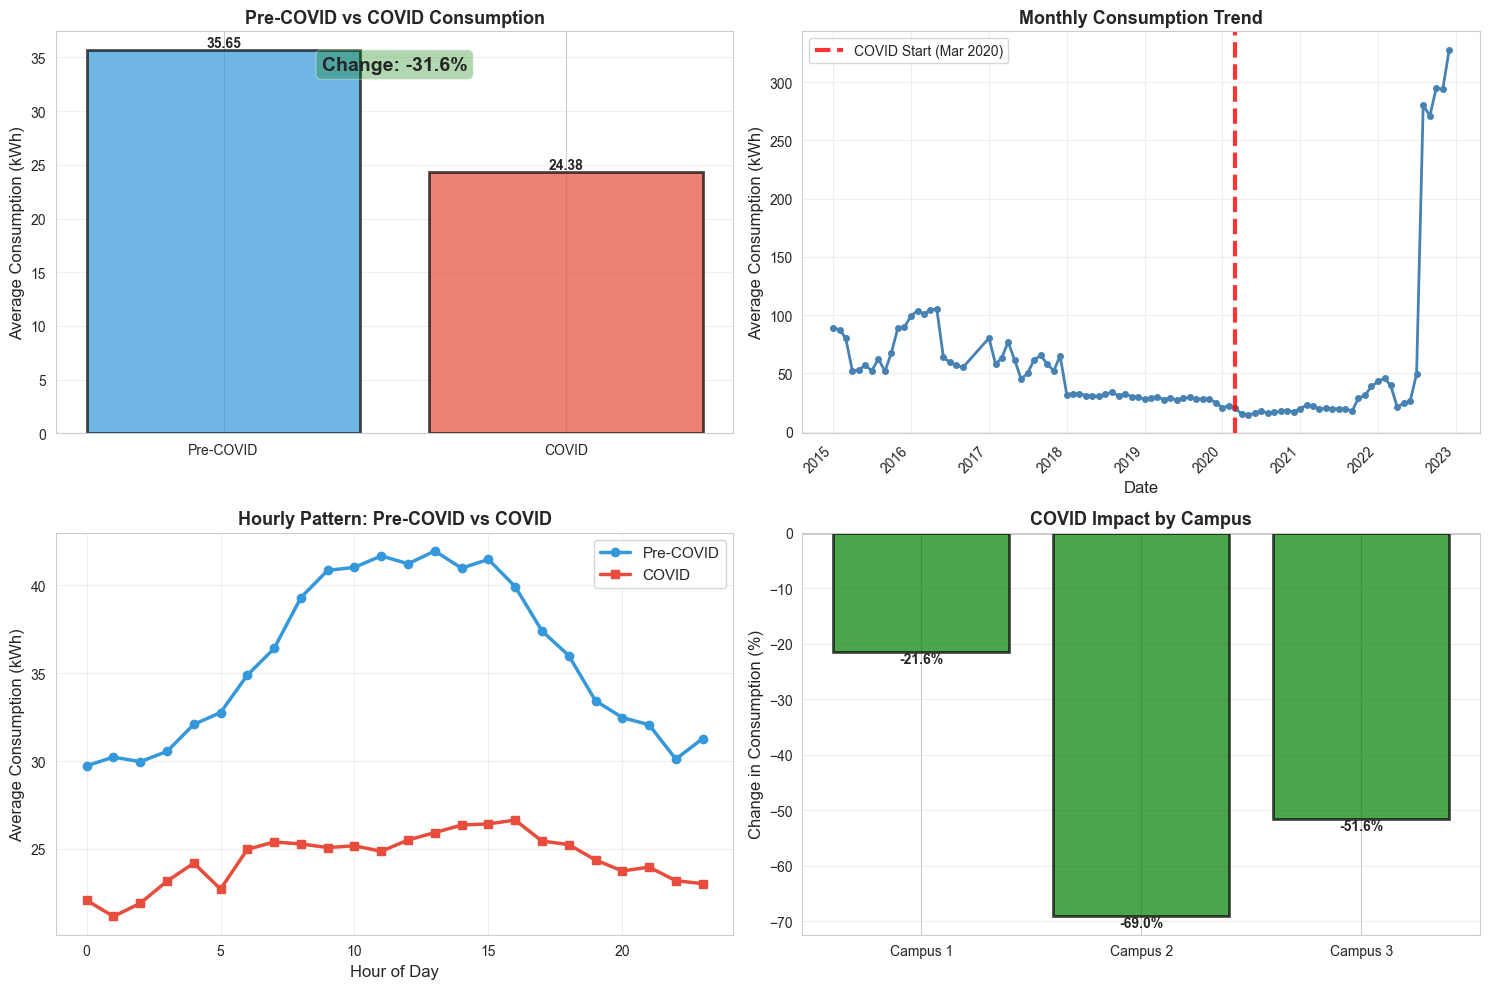


Key Observations:
  Major reduction during COVID - likely campus closures/remote work

Implications for Energy Management:
  Buildings can operate efficiently at reduced occupancy
  Remote work policies could provide permanent energy savings
  Opportunity to optimize systems for variable occupancy


In [38]:
# Cell 19: Visualize COVID impact

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Overall comparison bar chart
ax1 = axes[0, 0]
periods = ['Pre-COVID', 'COVID']
averages = [pre_covid_avg, covid_avg]
colors = ['#3498db', '#e74c3c']

bars = ax1.bar(periods, averages, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax1.set_title('Pre-COVID vs COVID Consumption', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}',
            ha='center', va='bottom', fontweight='bold')

# Add percentage change annotation
change_color = 'green' if change_pct < 0 else 'red'
ax1.text(0.5, max(averages) * 0.95, f'Change: {change_pct:+.1f}%',
        ha='center', fontsize=14, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor=change_color, alpha=0.3))

# Plot 2: Monthly trend across COVID transition
ax2 = axes[0, 1]
df_all['year_month'] = df_all['timestamp'].dt.to_period('M')
monthly_avg = df_all.groupby('year_month')['consumption'].mean()

# Convert period to timestamp for plotting
monthly_avg.index = monthly_avg.index.to_timestamp()

ax2.plot(monthly_avg.index, monthly_avg.values, linewidth=2, color='steelblue', marker='o', markersize=4)
ax2.axvline(x=covid_start, color='red', linestyle='--', linewidth=3, label='COVID Start (Mar 2020)', alpha=0.8)
ax2.set_xlabel('Date', fontsize=12)
ax2.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax2.set_title('Monthly Consumption Trend', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

# Plot 3: Hourly pattern comparison
ax3 = axes[1, 0]
pre_covid_hourly = pre_covid.groupby('hour')['consumption'].mean()
covid_hourly = covid.groupby('hour')['consumption'].mean()

ax3.plot(pre_covid_hourly.index, pre_covid_hourly.values, marker='o', linewidth=2.5,
        label='Pre-COVID', color='#3498db', markersize=6)
ax3.plot(covid_hourly.index, covid_hourly.values, marker='s', linewidth=2.5,
        label='COVID', color='#e74c3c', markersize=6)
ax3.set_xlabel('Hour of Day', fontsize=12)
ax3.set_ylabel('Average Consumption (kWh)', fontsize=12)
ax3.set_title('Hourly Pattern: Pre-COVID vs COVID', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

# Plot 4: Campus comparison
ax4 = axes[1, 1]
campuses_list = [r['Campus'] for r in covid_results]
changes = [r['Change %'] for r in covid_results]
bar_colors = ['green' if c < 0 else 'red' for c in changes]

bars4 = ax4.bar(campuses_list, changes, color=bar_colors, alpha=0.7, edgecolor='black', linewidth=2)
ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax4.set_ylabel('Change in Consumption (%)', fontsize=12)
ax4.set_title('COVID Impact by Campus', fontsize=13, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

for bar in bars4:
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.1f}%',
            ha='center', va='bottom' if height > 0 else 'top', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey Observations:")
if change_pct < -10:
    print("  Major reduction during COVID - likely campus closures/remote work")
elif change_pct < -5:
    print("  Moderate reduction during COVID - reduced occupancy")
elif abs(change_pct) < 5:
    print("  Minimal change - buildings maintained baseline operations")
else:
    print("  Increase during COVID - enhanced ventilation or other factors")

print("\nImplications for Energy Management:")
if change_pct < -5:
    print("  Buildings can operate efficiently at reduced occupancy")
    print("  Remote work policies could provide permanent energy savings")
    print("  Opportunity to optimize systems for variable occupancy")

In [39]:
# Cell 20: COVID Analysis - Summary and Insights

print("\n" + "="*70)
print("COVID-19 ANALYSIS: SUMMARY AND INSIGHTS")
print("="*70)

print("\nOVERALL FINDINGS:")
print(f"  Overall consumption change: {change_pct:+.1f}%")
print(f"  Statistical significance: {'Yes (p < 0.05)' if p_value_covid < 0.05 else 'No (p >= 0.05)'}")

print("\nCAMPUS-SPECIFIC PATTERNS:")
for result in covid_results:
    print(f"  {result['Campus']}: {result['Change %']:+.1f}% change")

print("\n" + "-"*70)
print("PRACTICAL IMPLICATIONS")
print("-"*70)

if change_pct < -10:
    print("\n1. REMOTE WORK IMPACT")
    print("   Finding: Significant consumption drop suggests remote work effectiveness")
    print("   Recommendation: Consider hybrid work models for sustained savings")
    
    print("\n2. BASELINE CONSUMPTION ISSUE")
    print("   Finding: Large drop indicates high baseline consumption when empty")
    print("   Recommendation: Implement occupancy-based controls to reduce waste")
    
    print("\n3. FUTURE PLANNING")
    print("   Finding: Buildings can operate at lower consumption levels")
    print("   Recommendation: Set new efficiency targets based on COVID performance")

elif abs(change_pct) < 5:
    print("\n1. INFLEXIBLE SYSTEMS")
    print("   Finding: Consumption unchanged despite occupancy reduction")
    print("   Recommendation: Buildings need adaptive controls (HVAC, lighting)")
    
    print("\n2. ESSENTIAL OPERATIONS")
    print("   Finding: Base loads dominate consumption")
    print("   Recommendation: Audit non-occupancy-dependent systems")

else:
    print("\n1. INCREASED OPERATIONS")
    print("   Finding: Higher consumption during COVID")
    print("   Recommendation: Evaluate ventilation and safety measure costs")

print("\n" + "="*70)
print("LESSONS LEARNED FROM COVID-19")
print("="*70)

print("\n1. Buildings demonstrate consumption flexibility")
print("2. Occupancy has measurable impact on energy use")
print("3. Remote work policies can support sustainability goals")
print("4. Need for adaptive building management systems")
print("5. Importance of monitoring consumption vs occupancy ratios")

print("\n" + "="*70)




COVID-19 ANALYSIS: SUMMARY AND INSIGHTS

OVERALL FINDINGS:
  Overall consumption change: -31.6%
  Statistical significance: Yes (p < 0.05)

CAMPUS-SPECIFIC PATTERNS:
  Campus 1: -21.6% change
  Campus 2: -69.0% change
  Campus 3: -51.6% change

----------------------------------------------------------------------
PRACTICAL IMPLICATIONS
----------------------------------------------------------------------

1. REMOTE WORK IMPACT
   Finding: Significant consumption drop suggests remote work effectiveness
   Recommendation: Consider hybrid work models for sustained savings

2. BASELINE CONSUMPTION ISSUE
   Finding: Large drop indicates high baseline consumption when empty
   Recommendation: Implement occupancy-based controls to reduce waste

3. FUTURE PLANNING
   Finding: Buildings can operate at lower consumption levels
   Recommendation: Set new efficiency targets based on COVID performance

LESSONS LEARNED FROM COVID-19

1. Buildings demonstrate consumption flexibility
2. Occupancy h